# Google Play Store — Phase 2 Analysis & Preprocessing
**Label:** `Maximum Installs`

This notebook analyzes all 24 original columns before preprocessing, applies the requested feature handling, checks the `|correlation| >= 0.85` leakage rule, standardizes continuous inputs, and exports the cleaned dataset.



In [1]:
# If needed:
# !pip install pandas numpy matplotlib seaborn scikit-learn

import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 100)

## 1. Load and verify the 24-column dataset

In [2]:
CSV_PATH = "Google-Playstore.csv"

if not os.path.exists(CSV_PATH):
    csv_files = [f for f in os.listdir(".") if f.lower().endswith(".csv")]
    if len(csv_files) == 1:
        CSV_PATH = csv_files[0]
    else:
        raise FileNotFoundError("Set CSV_PATH to the downloaded Kaggle CSV filename.")

df = pd.read_csv(CSV_PATH, low_memory=False)

expected_columns = [
    "App Name","App Id","Category","Rating","Rating Count","Installs",
    "Minimum Installs","Maximum Installs","Free","Price","Currency","Size",
    "Minimum Android","Developer Id","Developer Website","Developer Email",
    "Released","Last Updated","Content Rating","Privacy Policy","Ad Supported",
    "In App Purchases","Editors Choice","Scraped Time"
]

print("Loaded:", CSV_PATH)
print("Shape:", df.shape)
print("Columns:", len(df.columns))
display(df.head())

missing_expected = [c for c in expected_columns if c not in df.columns]
print("Missing expected columns:", missing_expected)
if missing_expected:
    raise ValueError("Dataset schema does not match the expected Google Play Store dataset.")

Loaded: Google-Playstore.csv
Shape: (2312944, 24)
Columns: 24


,App Name,App Id,Category,Rating,Rating Count,Installs,Minimum Installs,Maximum Installs,Free,Price,Currency,Size,Minimum Android,Developer Id,Developer Website,Developer Email,Released,Last Updated,Content Rating,Privacy Policy,Ad Supported,In App Purchases,Editors Choice,Scraped Time
0,Gakondo,com.ishakwe.gakondo,Adventure,0.0,0.0,10+,10.0,15,True,0.0,USD,10M,7.1 and up,Jean Confident Irénée NIYIZIBYOSE,https://beniyizibyose.tk/#/,jean21101999@gmail.com,"Feb 26, 2020","Feb 26, 2020",Everyone,https://beniyizibyose.tk/projects/,False,False,False,2021-06-15 20:19:35
1,Ampere Battery Info,com.webserveis.batteryinfo,Tools,4.4,64.0,"5,000+",5000.0,7662,True,0.0,USD,2.9M,5.0 and up,Webserveis,https://webserveis.netlify.app/,webserveis@gmail.com,"May 21, 2020","May 06, 2021",Everyone,https://dev4phones.wordpress.com/licencia-de-uso/,True,False,False,2021-06-15 20:19:35
2,Vibook,com.doantiepvien.crm,Productivity,0.0,0.0,50+,50.0,58,True,0.0,USD,3.7M,4.0.3 and up,Cabin Crew,NaN,vnacrewit@gmail.com,"Aug 9, 2019","Aug 19, 2019",Everyone,https://www.vietnamairlines.com/vn/en/terms-an...,False,False,False,2021-06-15 20:19:35
3,Smart City Trichy Public Service Vehicles 17UC...,cst.stJoseph.ug17ucs548,Communication,5.0,5.0,10+,10.0,19,True,0.0,USD,1.8M,4.0.3 and up,Climate Smart Tech2,http://www.climatesmarttech.com/,climatesmarttech2@gmail.com,"Sep 10, 2018","Oct 13, 2018",Everyone,NaN,True,False,False,2021-06-15 20:19:35
4,GROW.me,com.horodyski.grower,Tools,0.0,0.0,100+,100.0,478,True,0.0,USD,6.2M,4.1 and up,Rafal Milek-Horodyski,http://www.horodyski.com.pl,rmilekhorodyski@gmail.com,"Feb 21, 2020","Nov 12, 2018",Everyone,http://www.horodyski.com.pl,False,False,False,2021-06-15 20:19:35


Missing expected columns: []


## 2. Full original-feature analysis

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2312944 entries, 0 to 2312943
Data columns (total 24 columns):
 #   Column             Dtype  
---  ------             -----  
 0   App Name           object 
 1   App Id             object 
 2   Category           object 
 3   Rating             float64
 4   Rating Count       float64
 5   Installs           object 
 6   Minimum Installs   float64
 7   Maximum Installs   int64  
 8   Free               bool   
 9   Price              float64
 10  Currency           object 
 11  Size               object 
 12  Minimum Android    object 
 13  Developer Id       object 
 14  Developer Website  object 
 15  Developer Email    object 
 16  Released           object 
 17  Last Updated       object 
 18  Content Rating     object 
 19  Privacy Policy     object 
 20  Ad Supported       bool   
 21  In App Purchases   bool   
 22  Editors Choice     bool   
 23  Scraped Time       object 
dtypes: bool(4), float64(4), int64(1), object(15)
memor

In [4]:
missing_table = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing %": (df.isna().mean()*100).round(3),
    "Non-Missing Count": df.notna().sum()
}).sort_values("Missing %", ascending=False)
display(missing_table)

,Missing Count,Missing %,Non-Missing Count
Developer Website,760835,32.895,1552109
Privacy Policy,420953,18.200,1891991
Released,71053,3.072,2241891
Rating,22883,0.989,2290061
Rating Count,22883,0.989,2290061
Minimum Android,6530,0.282,2306414
Size,196,0.008,2312748
Currency,135,0.006,2312809
Minimum Installs,107,0.005,2312837
Installs,107,0.005,2312837


In [5]:
unique_table = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Unique Values": df.nunique(dropna=True),
    "Missing Values": df.isna().sum()
}).sort_values("Unique Values", ascending=False)
display(unique_table)

,Data Type,Unique Values,Missing Values
App Id,object,2312944,0
App Name,object,2177943,5
Privacy Policy,object,977743,420953
Developer Email,object,950456,31
Developer Website,object,810440,760835
Developer Id,object,758371,33
Maximum Installs,int64,251563,0
Scraped Time,object,67374,0
Rating Count,float64,38482,22883
Released,object,4158,71053


In [6]:
display(df.describe(include=[np.number]).T)
display(df.describe(include=["object","bool"]).T)

,count,mean,std,min,25%,50%,75%,max
Rating,2290061.0,2.203152,2.106223e+00,0.0,0.0,2.9,4.3,5.000000e+00
Rating Count,2290061.0,2864.838877,2.121626e+05,0.0,0.0,6.0,42.0,1.385576e+08
Minimum Installs,2312837.0,183445.213958,1.513144e+07,0.0,50.0,500.0,5000.0,1.000000e+10
Maximum Installs,2312944.0,320201.713137,2.355495e+07,0.0,84.0,695.0,7354.0,1.205763e+10
Price,2312944.0,0.103499,2.633127e+00,0.0,0.0,0.0,0.0,4.000000e+02


,count,unique,top,freq
App Name,2312939,2177943,Tic Tac Toe,382
App Id,2312944,2312944,com.ishakwe.gakondo,1
Category,2312944,48,Education,241090
Installs,2312837,22,100+,443368
Free,2312944,2,True,2267876
Currency,2312809,15,USD,2311548
Size,2312748,1657,Varies with device,74777
Minimum Android,2306414,154,4.1 and up,604465
Developer Id,2312911,758371,Subsplash Inc,5422
Developer Website,1552109,810440,http://www.subsplash.com/,7519


## 3. Label distribution

count    2.312944e+06
mean     3.202017e+05
std      2.355495e+07
min      0.000000e+00
25%      8.400000e+01
50%      6.950000e+02
75%      7.354000e+03
max      1.205763e+10
Name: Maximum Installs, dtype: float64
Missing label: 0


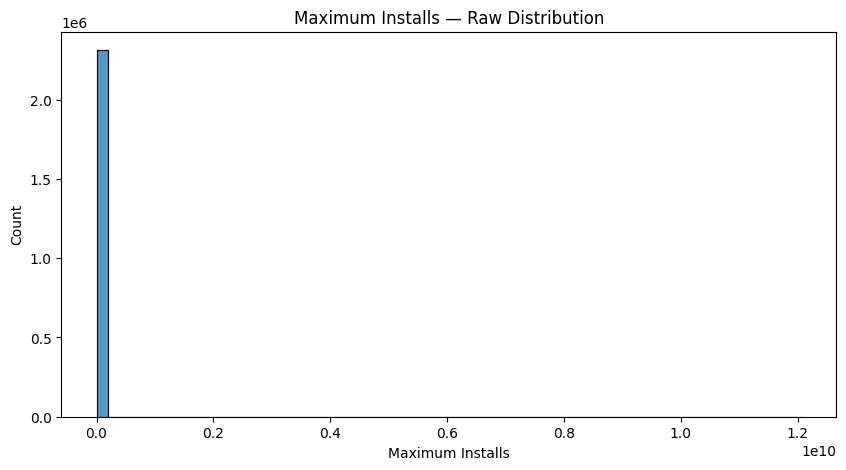

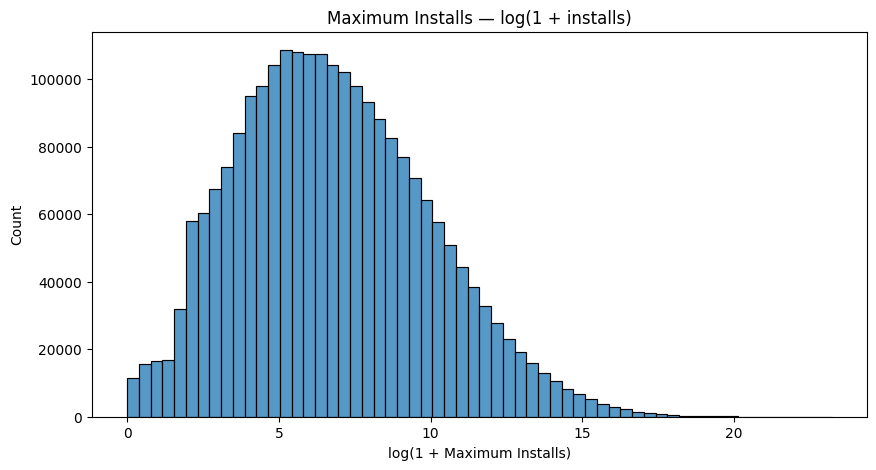

In [7]:
TARGET = "Maximum Installs"
LOG_TARGET = "Log_Max_Installs"
df[LOG_TARGET] = np.log1p(df[TARGET])
print(df[TARGET].describe())
print("Missing label:", df[TARGET].isna().sum())

plt.figure(figsize=(10,5))
sns.histplot(df[TARGET].dropna(), bins=60)
plt.title("Maximum Installs — Raw Distribution")
plt.xlabel("Maximum Installs")
plt.ylabel("Count")

plt.savefig(
    "maximum_installs_raw_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.figure(figsize=(10,5))
sns.histplot(np.log1p(df[TARGET].dropna()), bins=60)
plt.title("Maximum Installs — log(1 + installs)")
plt.xlabel("log(1 + Maximum Installs)")
plt.ylabel("Count")

plt.savefig(
    "maximum_installs_log_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 4. Original correlations BEFORE dropping features


,Correlation,Absolute Correlation,>= 0.85
Minimum Installs (log),0.989961,0.989961,True
Rating Count (log),0.866671,0.866671,True
Rating,0.647185,0.647185,False
Ad Supported,0.252051,0.252051,False
In App Purchases,0.247572,0.247572,False
Editors Choice,0.055253,0.055253,False
Free,0.052433,0.052433,False
Price (log),-0.047227,0.047227,False


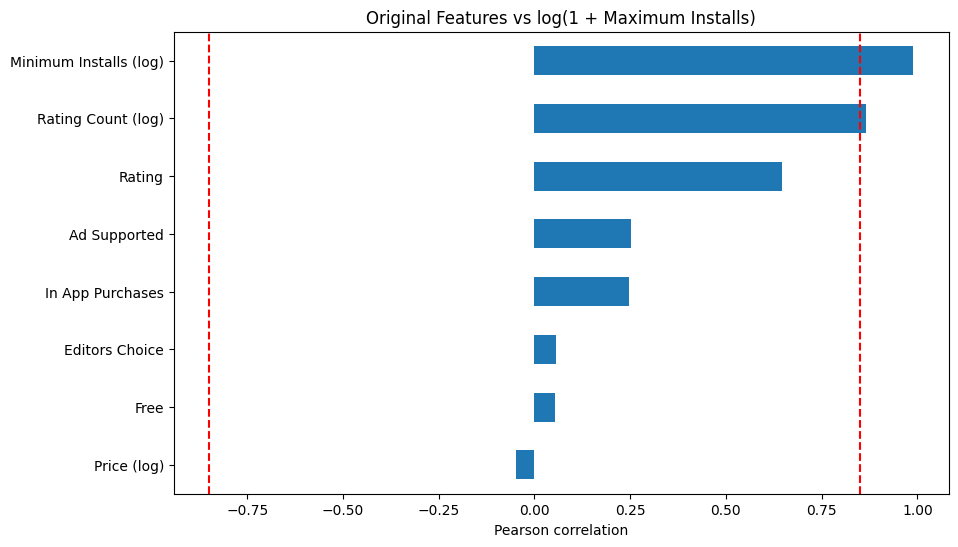

In [8]:
# Skewed count columns are log-transformed too, for the same reason as the label.
# Boolean columns are included so every feature gets a correlation value.
analysis = pd.DataFrame({
    "Minimum Installs (log)": np.log1p(df["Minimum Installs"]),
    "Rating Count (log)":     np.log1p(df["Rating Count"]),
    "Rating":                 df["Rating"],
    "Price (log)":            np.log1p(df["Price"]),
    "Free":                   df["Free"].astype(int),
    "Ad Supported":           df["Ad Supported"].astype(int),
    "In App Purchases":       df["In App Purchases"].astype(int),
    "Editors Choice":         df["Editors Choice"].astype(int),
})

corr_with_target = (analysis.corrwith(df[LOG_TARGET])
                    .sort_values(key=lambda x: x.abs(), ascending=False))
corr_table = pd.DataFrame({
    "Correlation": corr_with_target,
    "Absolute Correlation": corr_with_target.abs(),
    ">= 0.85": corr_with_target.abs() >= 0.85
})
display(corr_table)

plt.figure(figsize=(10,6))
corr_with_target.sort_values().plot(kind="barh")
plt.axvline(0.85, linestyle="--", color="red")
plt.axvline(-0.85, linestyle="--", color="red")
plt.title("Original Features vs log(1 + Maximum Installs)")
plt.xlabel("Pearson correlation")
plt.show()

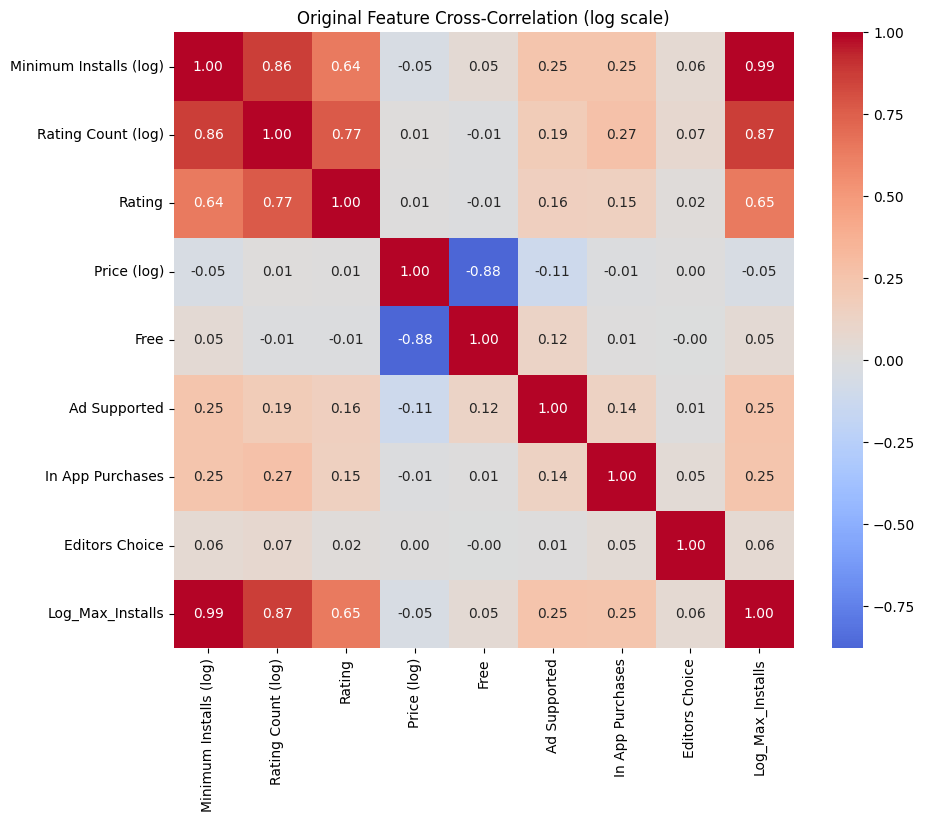

In [9]:
plt.figure(figsize=(10,8))
sns.heatmap(analysis.assign(**{LOG_TARGET: df[LOG_TARGET]}).corr(),
            annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Original Feature Cross-Correlation (log scale)")
plt.savefig(
    "original_cross_correlation.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 5. Major categorical/Boolean distributions


==== Category ====
Unique: 48


,Count
Category,
Education,241090
Music & Audio,154906
Tools,143988
Business,143771
Entertainment,138276
Lifestyle,118331
Books & Reference,116728
Personalization,89210
Health & Fitness,83510


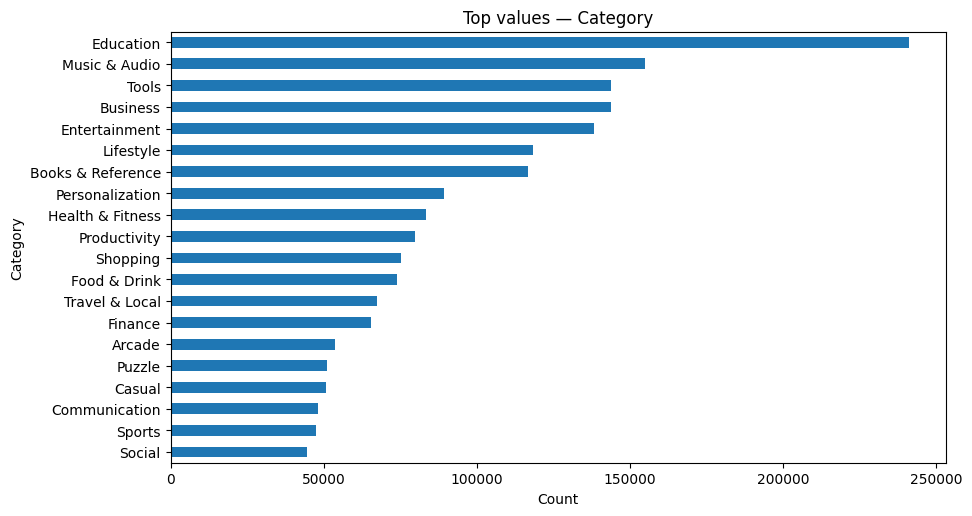


==== Content Rating ====
Unique: 6


,Count
Content Rating,
Everyone,2022089
Teen,196375
Mature 17+,60289
Everyone 10+,33901
Unrated,154
Adults only 18+,136


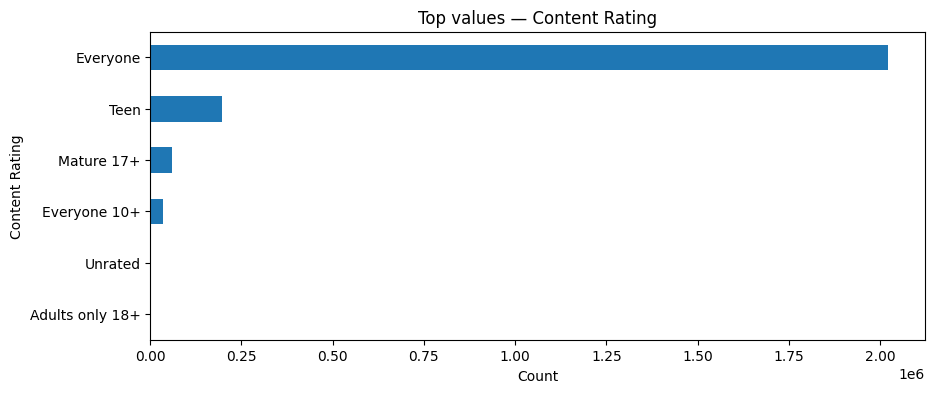


==== Currency ====
Unique: 15


,Count
Currency,
USD,2311548
XXX,1236
NaN,135
EUR,6
INR,5
GBP,3
CAD,2
VND,1
BRL,1


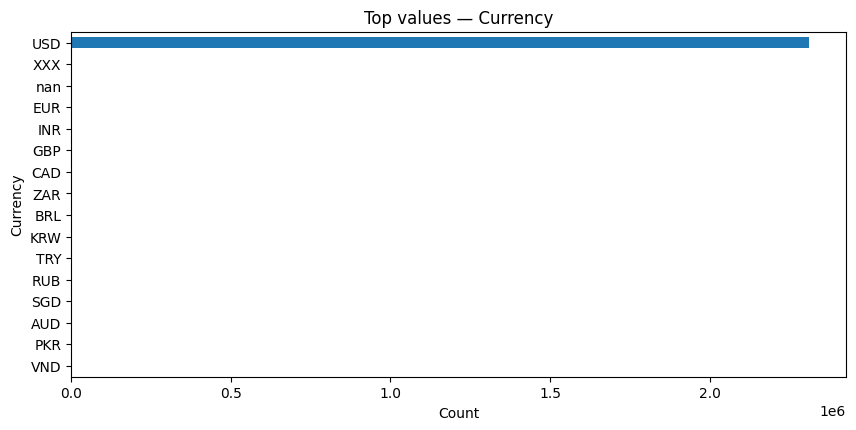


==== Free ====
Unique: 2


,Count
Free,
True,2267876
False,45068


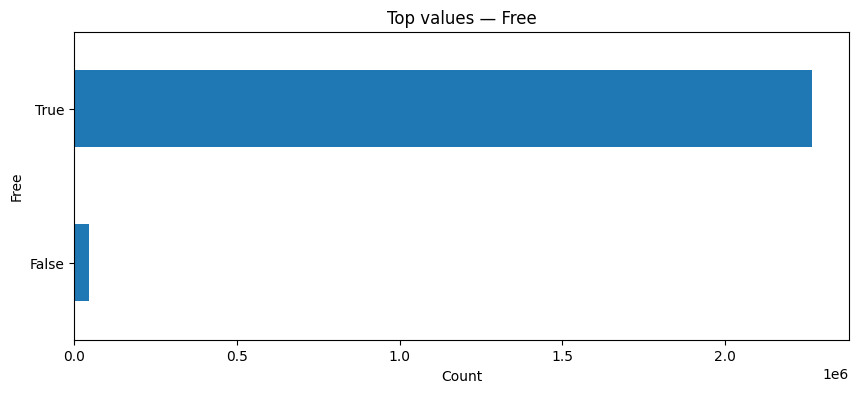


==== Ad Supported ====
Unique: 2


,Count
Ad Supported,
False,1162170
True,1150774


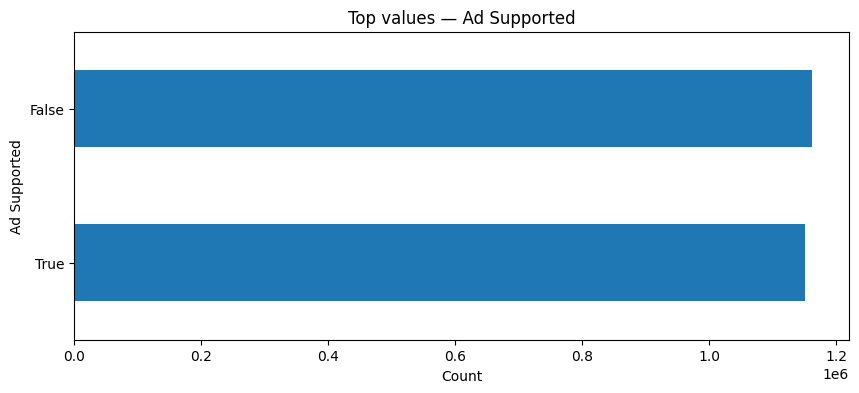


==== In App Purchases ====
Unique: 2


,Count
In App Purchases,
False,2117635
True,195309


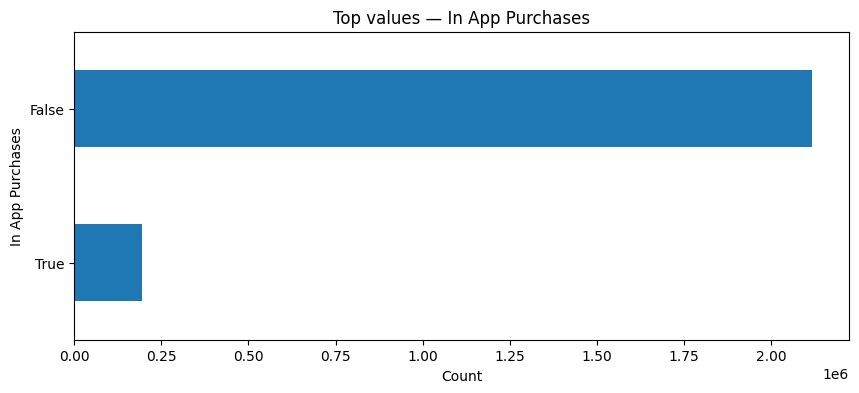


==== Editors Choice ====
Unique: 2


,Count
Editors Choice,
False,2312091
True,853


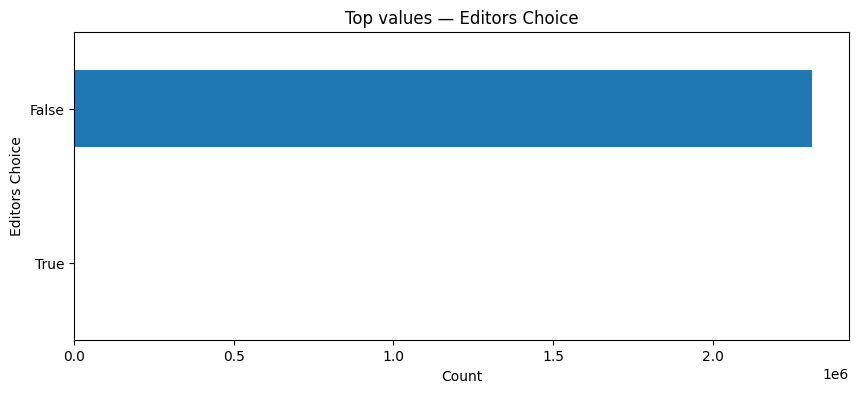

In [10]:
for col in ["Category","Content Rating","Currency","Free",
            "Ad Supported","In App Purchases","Editors Choice"]:
    print("\n====", col, "====")
    print("Unique:", df[col].nunique(dropna=True))
    display(df[col].value_counts(dropna=False).head(30).to_frame("Count"))

    top = df[col].astype(str).value_counts().head(20)
    plt.figure(figsize=(10, max(4, len(top)*0.28)))
    top.sort_values().plot(kind="barh")
    plt.title("Top values — " + col)
    plt.xlabel("Count")
    plt.show()

## 6. Start preprocessing
Rows with missing `Maximum Installs` cannot be used for supervised learning, so they are removed.

In [11]:
work = df.copy()
before = len(work)
work = work.dropna(subset=[TARGET]).copy()
print("Rows removed for missing label:", before-len(work))
print("Remaining:", len(work))

# From here on, the log label is the target; drop the raw column so it can't leak in
work = work.drop(columns=[TARGET])
TARGET = LOG_TARGET

Rows removed for missing label: 0
Remaining: 2312944


### 6.1 Free and Ad Supported → binary

In [12]:
def to_binary(series):
    mapping = {
        True:1, False:0, "True":1, "False":0, "true":1, "false":0,
        "TRUE":1, "FALSE":0, 1:1, 0:0, "1":1, "0":0
    }
    return series.map(mapping)

work["Free"] = to_binary(work["Free"]).fillna(0).astype("int8")
work["Ad Supported"] = to_binary(work["Ad Supported"]).fillna(0).astype("int8")

display(work[["Free","Ad Supported"]].head())

,Free,Ad Supported
0,1,0
1,1,1
2,1,0
3,1,1
4,1,0


### 6.2 Size → MB → tiers
Chosen interpretable tiers:
- Tiny: < 10 MB
- Small: 10–<30 MB
- Medium: 30–<100 MB
- Large: 100–<300 MB
- Very Large: >=300 MB

`Varies with device` is treated as missing. Missing parsed sizes are median-imputed before tiering.

In [13]:
def size_to_mb(value):
    if pd.isna(value):
        return np.nan
    s = str(value).strip().replace(",","").lower()
    if "varies" in s or s in {"","nan","none"}:
        return np.nan
    m = re.search(r"([0-9]*\.?[0-9]+)\s*([kmg]?)", s)
    if not m:
        return np.nan
    number = float(m.group(1))
    unit = m.group(2)
    if unit == "k":
        return number/1024
    if unit == "g":
        return number*1024
    return number

work["Size_MB"] = work["Size"].apply(size_to_mb)
print("Parsed Size_MB:")
display(work["Size_MB"].describe().to_frame())

size_median = work["Size_MB"].median()
work["Size_MB"] = work["Size_MB"].fillna(size_median)

work["Size_Tier"] = pd.cut(
    work["Size_MB"],
    bins=[-np.inf,10,30,100,300,np.inf],
    labels=["Tiny","Small","Medium","Large","Very_Large"],
    right=False
)
display(work["Size_Tier"].value_counts(dropna=False).to_frame("Count"))

Parsed Size_MB:


,Size_MB
count,2.237971e+06
mean,1.920829e+01
std,2.404863e+01
min,3.125000e-03
25%,4.900000e+00
50%,1.000000e+01
75%,2.500000e+01
max,1.536000e+03


,Count
Size_Tier,
Tiny,1100614
Small,757207
Medium,425676
Large,29026
Very_Large,421


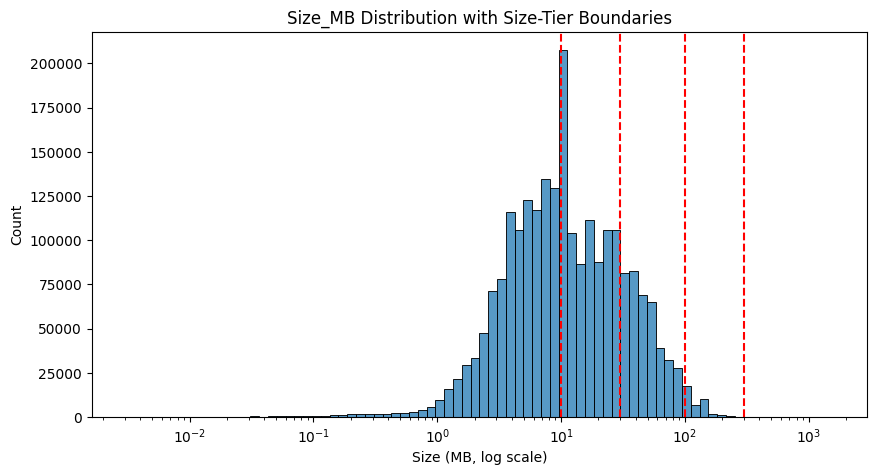

In [ ]:

plt.figure(figsize=(10,5))
sns.histplot(work["Size_MB"], bins=80, log_scale=True)
for boundary in [10, 30, 100, 300]:
    plt.axvline(boundary, linestyle="--", color="red")
plt.title("Size_MB Distribution with Size-Tier Boundaries")
plt.xlabel("Size (MB, log scale)")
plt.ylabel("Count")

plt.savefig(
    "size_mb_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 6.3 Minimum Android → numeric version
Examples such as `4.1 and up` become `4.1`. `Varies with device` becomes missing and is median-imputed.

In [15]:
def parse_android_version(value):
    if pd.isna(value):
        return np.nan
    s = str(value).strip().lower()
    if "varies" in s or s in {"","nan","none"}:
        return np.nan
    m = re.search(r"(\d+(?:\.\d+)?)", s)
    return float(m.group(1)) if m else np.nan

work["Minimum_Android_Numeric"] = work["Minimum Android"].apply(parse_android_version)
android_median = work["Minimum_Android_Numeric"].median()
work["Minimum_Android_Numeric"] = work["Minimum_Android_Numeric"].fillna(android_median)

print("Median Android version used:", android_median)
display(work["Minimum_Android_Numeric"].describe().to_frame())

Median Android version used: 4.2


,Minimum_Android_Numeric
count,2.312944e+06
mean,4.346075e+00
std,8.528387e-01
min,1.000000e+00
25%,4.100000e+00
50%,4.200000e+00
75%,5.000000e+00
max,8.000000e+00


### 6.4 Developer Id → frequency coding

In [16]:
dev = work["Developer Id"].fillna("__MISSING_DEVELOPER__")
dev_freq = dev.value_counts(normalize=True)
work["Developer_Frequency"] = dev.map(dev_freq)

display(work[["Developer Id","Developer_Frequency"]].head())
display(work["Developer_Frequency"].describe().to_frame())

,Developer Id,Developer_Frequency
0,Jean Confident Irénée NIYIZIBYOSE,1.297048e-06
1,Webserveis,6.917591e-06
2,Cabin Crew,1.297048e-06
3,Climate Smart Tech2,7.349940e-06
4,Rafal Milek-Horodyski,4.323494e-07


,Developer_Frequency
count,2.312944e+06
mean,4.847561e-05
std,2.112107e-04
min,4.323494e-07
25%,8.646988e-07
50%,3.026446e-06
75%,1.686163e-05
max,2.344199e-03


### 6.5 Date engineering
- `App_Age_Months = Scraped Time - Released`
- `Months_Since_Last_Update = absolute(Scraped Time - Last Updated)`

In [17]:
for c in ["Released","Last Updated","Scraped Time"]:
    work[c] = pd.to_datetime(work[c], errors="coerce")

work["App_Age_Months"] = (
    (work["Scraped Time"]-work["Released"]).dt.total_seconds()
    /(60*60*24*30.44)
)
work.loc[work["App_Age_Months"] < 0, "App_Age_Months"] = np.nan

work["Months_Since_Last_Update"] = (
    (work["Scraped Time"]-work["Last Updated"]).dt.total_seconds().abs()
    /(60*60*24*30.44)
)

for c in ["App_Age_Months","Months_Since_Last_Update"]:
    med = work[c].median()
    work[c] = work[c].fillna(med)
    print(c, "median imputation:", round(med,3))

display(work[["App_Age_Months","Months_Since_Last_Update"]].describe().T)

App_Age_Months median imputation: 26.889
Months_Since_Last_Update median imputation: 13.023


,count,mean,std,min,25%,50%,75%,max
App_Age_Months,2312944.0,33.347405,25.049755,0.018003,14.396306,26.888995,46.659929,136.580949
Months_Since_Last_Update,2312944.0,18.345720,18.237869,0.002205,4.303050,13.022608,25.963728,148.172529


### 6.6 Content Rating → Everyone flag
`Everyone` = 1; every other rating = 0.

**Report limitation:** this is simple and interpretable, but it loses distinctions among Everyone 10+, Teen, Mature 17+, etc. Full one-hot encoding would preserve more information.

In [18]:
work["Is_Everyone"] = (
    work["Content Rating"].fillna("").str.strip().str.lower()
    .eq("everyone").astype("int8")
)
display(pd.crosstab(work["Content Rating"].fillna("MISSING"), work["Is_Everyone"], margins=True))

Is_Everyone,0,1,All
Content Rating,,,
Adults only 18+,136,0,136
Everyone,0,2022089,2022089
Everyone 10+,33901,0,33901
Mature 17+,60289,0,60289
Teen,196375,0,196375
Unrated,154,0,154
All,290855,2022089,2312944


### 6.7 Privacy Policy → Has Privacy Policy flag

In [19]:
work["Has_Privacy_Policy"] = work["Privacy Policy"].notna().astype("int8")
display(work["Has_Privacy_Policy"].value_counts().to_frame("Count"))

,Count
Has_Privacy_Policy,
1,1891991
0,420953


### 6.8 Category → one-hot encoding

In [20]:
work["Category"] = work["Category"].fillna("Missing").astype(str)
work["Category"] = work["Category"].replace({"Educational": "Education", "Music": "Music & Audio"})
print("Category count:", work["Category"].nunique())
display(work["Category"].value_counts().to_frame("Count"))

Category count: 46


,Count
Category,
Education,262398
Music & Audio,159108
Tools,143988
Business,143771
Entertainment,138276
Lifestyle,118331
Books & Reference,116728
Personalization,89210
Health & Fitness,83510


## 7. Drop the requested original features


In [21]:
columns_to_drop = [
    "App Name","App Id","Rating","Rating Count","Installs","Minimum Installs",
    "Price","Currency","Size","Minimum Android","Developer Id",
    "Developer Website","Developer Email","Released","Last Updated",
    "Content Rating","Privacy Policy","In App Purchases","Editors Choice",
    "Scraped Time"
]
work = work.drop(columns=columns_to_drop, errors="ignore")

print("Remaining before one-hot encoding:", work.shape)
print(work.columns.tolist())

Remaining before one-hot encoding: (2312944, 12)
['Category', 'Free', 'Ad Supported', 'Log_Max_Installs', 'Size_MB', 'Size_Tier', 'Minimum_Android_Numeric', 'Developer_Frequency', 'App_Age_Months', 'Months_Since_Last_Update', 'Is_Everyone', 'Has_Privacy_Policy']


## 8. One-hot encode Category and Size Tier

In [22]:
work = pd.get_dummies(
    work,
    columns=["Category","Size_Tier"],
    prefix=["Category","Size"],
    dtype="int8"
)
print("Shape after one-hot encoding:", work.shape)
display(work.head())

Shape after one-hot encoding: (2312944, 61)


,Free,Ad Supported,Log_Max_Installs,Size_MB,Minimum_Android_Numeric,Developer_Frequency,App_Age_Months,Months_Since_Last_Update,Is_Everyone,Has_Privacy_Policy,Category_Action,Category_Adventure,Category_Arcade,Category_Art & Design,Category_Auto & Vehicles,Category_Beauty,Category_Board,Category_Books & Reference,Category_Business,Category_Card,Category_Casino,Category_Casual,Category_Comics,Category_Communication,Category_Dating,Category_Education,Category_Entertainment,Category_Events,Category_Finance,Category_Food & Drink,Category_Health & Fitness,Category_House & Home,Category_Libraries & Demo,Category_Lifestyle,Category_Maps & Navigation,Category_Medical,Category_Music & Audio,Category_News & Magazines,Category_Parenting,Category_Personalization,Category_Photography,Category_Productivity,Category_Puzzle,Category_Racing,Category_Role Playing,Category_Shopping,Category_Simulation,Category_Social,Category_Sports,Category_Strategy,Category_Tools,Category_Travel & Local,Category_Trivia,Category_Video Players & Editors,Category_Weather,Category_Word,Size_Tiny,Size_Small,Size_Medium,Size_Large,Size_Very_Large
0,1,0,2.772589,10.0,7.1,1.297048e-06,15.632291,15.632291,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
1,1,1,8.944159,2.9,5.0,6.917591e-06,12.839912,1.341883,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0
2,1,0,4.077537,3.7,4.0,1.297048e-06,22.235445,21.906929,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
3,1,1,2.995732,1.8,4.0,7.349940e-06,33.174998,32.090898,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
4,1,0,6.171701,6.2,4.1,4.323494e-07,15.796548,31.105353,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0


## 9. Engineered-feature correlations and automatic leakage check
Any remaining input with absolute target correlation >= 0.85 is dropped automatically.

In [23]:
numeric = work.select_dtypes(include=np.number).columns.tolist()
final_corr = (
    work[numeric].corr(numeric_only=True)[TARGET]
    .drop(TARGET)
    .sort_values(key=lambda x:x.abs(), ascending=False)
)
final_corr_table = pd.DataFrame({
    "Correlation": final_corr,
    "Absolute Correlation": final_corr.abs(),
    "Drop (>=0.85)": final_corr.abs() >= 0.85
})
display(final_corr_table)

leakage_features = final_corr[final_corr.abs() >= 0.85].index.tolist()
print("Leakage-threshold features:", leakage_features)

if leakage_features:
    work = work.drop(columns=leakage_features)
    print("Dropped due to professor's >=0.85 rule:", leakage_features)

,Correlation,Absolute Correlation,Drop (>=0.85)
App_Age_Months,0.369447,0.369447,False
Ad Supported,0.252051,0.252051,False
Developer_Frequency,-0.124090,0.124090,False
Has_Privacy_Policy,0.115609,0.115609,False
Category_Business,-0.107934,0.107934,False
Category_Simulation,0.097425,0.097425,False
Minimum_Android_Numeric,-0.092536,0.092536,False
Category_Food & Drink,-0.083926,0.083926,False
Size_MB,0.080912,0.080912,False
Size_Medium,0.076960,0.076960,False


Leakage-threshold features: []


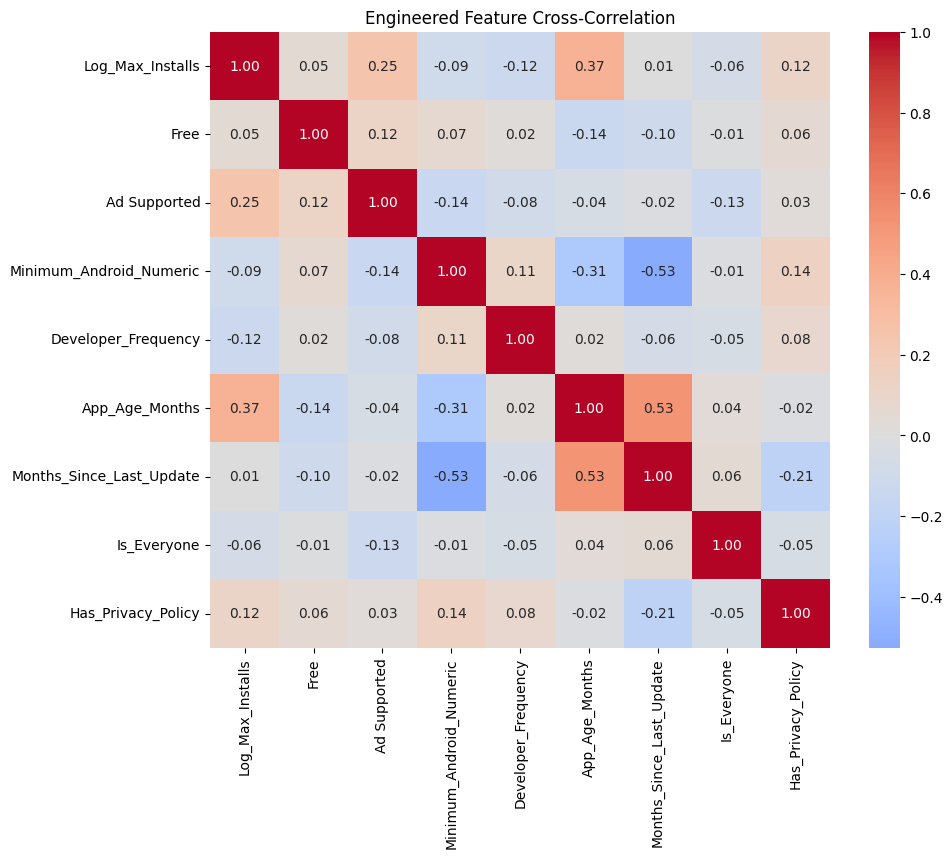

In [24]:
main_numeric = [c for c in [
    TARGET,"Free","Ad Supported","Minimum_Android_Numeric",
    "Developer_Frequency","App_Age_Months","Months_Since_Last_Update",
    "Is_Everyone","Has_Privacy_Policy"
] if c in work.columns]

plt.figure(figsize=(10,8))
sns.heatmap(work[main_numeric].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0)
plt.title("Engineered Feature Cross-Correlation")
plt.savefig(
    "engineered_cross_correlation.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

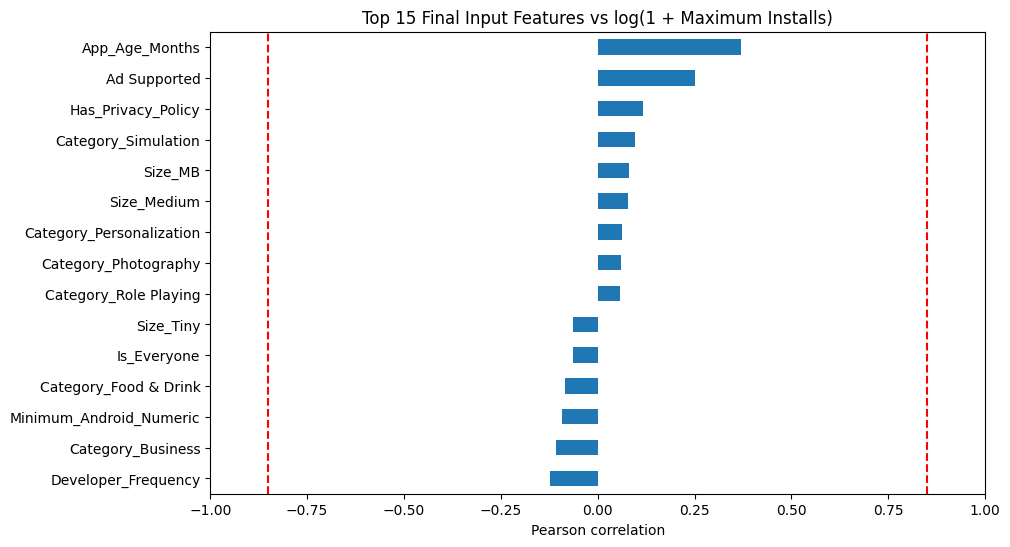

In [ ]:

top_corr = final_corr.head(15).sort_values()

plt.figure(figsize=(10,6))
top_corr.plot(kind="barh")
plt.axvline(0.85, linestyle="--", color="red")
plt.axvline(-0.85, linestyle="--", color="red")
plt.xlim(-1, 1)
plt.title("Top 15 Final Input Features vs log(1 + Maximum Installs)")
plt.xlabel("Pearson correlation")

plt.savefig(
    "final_feature_target_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 10. Standardization
Continuous inputs are standardized. Binary and one-hot features are left as 0/1, and the label stays in original install units.



In [26]:
continuous_candidates = [
    "Minimum_Android_Numeric",
    "Developer_Frequency",
    "App_Age_Months",
    "Months_Since_Last_Update"
]
continuous_features = [c for c in continuous_candidates if c in work.columns]

scaler = StandardScaler()
work[continuous_features] = scaler.fit_transform(work[continuous_features])

scaler_parameters = pd.DataFrame({
    "Feature": continuous_features,
    "Mean": scaler.mean_,
    "Scale_Std": scaler.scale_
})
display(scaler_parameters)

,Feature,Mean,Scale_Std
0,Minimum_Android_Numeric,4.346075,0.852839
1,Developer_Frequency,0.000048,0.000211
2,App_Age_Months,33.347405,25.049749
3,Months_Since_Last_Update,18.345720,18.237865


## 11. Final validation

In [27]:
non_numeric = work.drop(columns=[TARGET]).select_dtypes(exclude=np.number).columns.tolist()

print("Final shape:", work.shape)
print("Rows:", work.shape[0])
print("Input features:", work.shape[1]-1)
print("Label:", TARGET)
print("Non-numeric inputs:", non_numeric)
print("Remaining missing cells:", int(work.isna().sum().sum()))
print("Duplicate rows:", int(work.duplicated().sum()))

print("\nFINAL FEATURES")
for i,c in enumerate([c for c in work.columns if c != TARGET],1):
    print(f"{i:3}. {c}")

Final shape: (2312944, 61)
Rows: 2312944
Input features: 60
Label: Log_Max_Installs
Non-numeric inputs: []
Remaining missing cells: 0
Duplicate rows: 0

FINAL FEATURES
  1. Free
  2. Ad Supported
  3. Size_MB
  4. Minimum_Android_Numeric
  5. Developer_Frequency
  6. App_Age_Months
  7. Months_Since_Last_Update
  8. Is_Everyone
  9. Has_Privacy_Policy
 10. Category_Action
 11. Category_Adventure
 12. Category_Arcade
 13. Category_Art & Design
 14. Category_Auto & Vehicles
 15. Category_Beauty
 16. Category_Board
 17. Category_Books & Reference
 18. Category_Business
 19. Category_Card
 20. Category_Casino
 21. Category_Casual
 22. Category_Comics
 23. Category_Communication
 24. Category_Dating
 25. Category_Education
 26. Category_Entertainment
 27. Category_Events
 28. Category_Finance
 29. Category_Food & Drink
 30. Category_Health & Fitness
 31. Category_House & Home
 32. Category_Libraries & Demo
 33. Category_Lifestyle
 34. Category_Maps & Navigation
 35. Category_Medical
 36. Ca

In [28]:
display(work.describe().T)

,count,mean,std,min,25%,50%,75%,max
Free,2312944.0,9.805149e-01,0.138223,0.000000,1.000000,1.000000,1.000000,1.000000
Ad Supported,2312944.0,4.975365e-01,0.499994,0.000000,0.000000,0.000000,1.000000,1.000000
Log_Max_Installs,2312944.0,6.796706e+00,3.161497,0.000000,4.442651,6.545350,8.903136,23.212963
Size_MB,2312944.0,1.890980e+01,23.711798,0.003125,5.100000,10.000000,24.000000,1536.000000
Minimum_Android_Numeric,2312944.0,-6.901985e-16,1.000000,-3.923457,-0.288537,-0.171281,0.766763,4.284427
Developer_Frequency,2312944.0,-3.740501e-17,1.000000,-0.227466,-0.225419,-0.215184,-0.149680,10.869353
App_Age_Months,2312944.0,1.831911e-16,1.000000,-1.330528,-0.756538,-0.257823,0.531443,4.121141
Months_Since_Last_Update,2312944.0,7.308968e-17,1.000000,-1.005793,-0.769973,-0.291871,0.417703,7.118531
Is_Everyone,2312944.0,8.742490e-01,0.331569,0.000000,1.000000,1.000000,1.000000,1.000000
Has_Privacy_Policy,2312944.0,8.180012e-01,0.385844,0.000000,1.000000,1.000000,1.000000,1.000000


## 12. Before/after metrics

In [29]:
summary = pd.DataFrame({
    "Metric":[
        "Original rows","Original columns","Cleaned rows",
        "Cleaned columns including label","Final input features",
        "Remaining missing cells"
    ],
    "Value":[
        df.shape[0],df.shape[1],work.shape[0],work.shape[1],
        work.shape[1]-1,int(work.isna().sum().sum())
    ]
})
display(summary)

,Metric,Value
0,Original rows,2312944
1,Original columns,25
2,Cleaned rows,2312944
3,Cleaned columns including label,61
4,Final input features,60
5,Remaining missing cells,0


## 13. Export deliverables

In [30]:
work.to_csv("google_playstore_cleaned.csv", index=False)
missing_table.to_csv("original_missing_values_analysis.csv")
unique_table.to_csv("original_unique_values_analysis.csv")
corr_table.to_csv("original_target_correlations.csv")
final_corr_table.to_csv("engineered_target_correlations.csv")
scaler_parameters.to_csv("scaler_parameters.csv", index=False)

print("Created:")
print("  google_playstore_cleaned.csv")
print("  original_missing_values_analysis.csv")
print("  original_unique_values_analysis.csv")
print("  original_target_correlations.csv")
print("  engineered_target_correlations.csv")
print("  scaler_parameters.csv")

Created:
  google_playstore_cleaned.csv
  original_missing_values_analysis.csv
  original_unique_values_analysis.csv
  original_target_correlations.csv
  engineered_target_correlations.csv
  scaler_parameters.csv
